In [1]:
import os
import re
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import find_peaks

In [5]:
# Dataset 1
def extract_uvvis_normalized(h5_file_path, wavelength_range=(220, 700), resolution=1):
    df = pd.DataFrame()
    wavelengths = np.arange(*wavelength_range, step=resolution)

    with h5py.File(h5_file_path, 'r') as hdf:
        for name in hdf:
            dataset = hdf[name]
            spectrum = np.array(dataset)
            attrs = dataset.attrs

            # Interpolate absorbance to uniform wavelength grid
            absorbance_interp = np.interp(wavelengths, spectrum[:, 0], spectrum[:, 1])
            
            # Step 1: Set any absorbance < 0 to 0
            absorbance_interp[absorbance_interp < 0] = 0

            # Step 2: Normalize by max absorbance (lambda max)
            max_abs = np.max(absorbance_interp)
            if max_abs > 0:
                absorbance_interp /= max_abs

            # Build row dictionary
            row = {"Dataset": name}
            row.update({f"abs_{int(w)}": a for w, a in zip(wavelengths, absorbance_interp)})

            df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)

    return df

# Dataset 2: ligand and metal control spectra for each sample
def extract_control_spectra_normalized(sample_h5, control_h5, wavelength_range=(220, 700), resolution=1):
    wavelengths = np.arange(*wavelength_range, step=resolution)

    def decode_attr(attr):
        return attr.decode('utf-8').strip() if isinstance(attr, bytes) else str(attr).strip()

    def normalize(spectrum):
        # Interpolate to the wavelength grid, set absorbance < 0 to 0, and normalize by max absorbance
        absorbance = np.interp(wavelengths, spectrum[:, 0], spectrum[:, 1])
        absorbance[absorbance < 0] = 0
        max_abs = np.max(absorbance)
        return absorbance / max_abs if max_abs > 0 else absorbance

    # Step 1: Index the control spectra
    ligand_controls = {}
    metal_controls = {}

    with h5py.File(control_h5, 'r') as hdf:
        for name in hdf:
            attrs = hdf[name].attrs
            ligand = decode_attr(attrs.get('Ligand', ''))
            metal = decode_attr(attrs.get('Metal', ''))
            solvent = decode_attr(attrs.get('Solvent', ''))
            base = decode_attr(attrs.get('Base', ''))

            if metal and not ligand:
                metal_controls[(metal, solvent, base)] = normalize(np.array(hdf[name]))
            elif ligand and not metal:
                ligand_controls[(ligand, solvent)] = normalize(np.array(hdf[name]))

    # Step 2: Look up each sample's ligand and metal control spectra
    rows = []
    missing_controls = []

    with h5py.File(sample_h5, 'r') as hdf:
        for name in hdf:
            attrs = hdf[name].attrs
            ligand = decode_attr(attrs.get('Ligand', ''))
            metal = decode_attr(attrs.get('Metal', ''))
            solvent = decode_attr(attrs.get('Solvent', ''))
            base = decode_attr(attrs.get('Base', ''))

            ligand_abs = ligand_controls.get((ligand, solvent))
            metal_abs = metal_controls.get((metal, solvent, base))
            if ligand_abs is None or metal_abs is None:
                missing_controls.append(name)

            row = {"Dataset": name}
            if ligand_abs is not None:
                row.update({f"ligand_abs_{int(w)}": a for w, a in zip(wavelengths, ligand_abs)})
            if metal_abs is not None:
                row.update({f"metal_abs_{int(w)}": a for w, a in zip(wavelengths, metal_abs)})
            rows.append(row)

    if missing_controls:
        print(f"{len(missing_controls)} samples without a matching ligand or metal control: {missing_controls}")

    return pd.DataFrame(rows)

# Helper function to find top peaks
def get_top_peaks(wavelengths, absorbance, top_n=5, **peak_kwargs):
    peaks, properties = find_peaks(absorbance, **peak_kwargs)
    if len(peaks) == 0:
        return [0] * top_n, 0
    top_indices = np.argsort(properties["peak_heights"])[-top_n:][::-1]
    top_wavelengths = wavelengths[peaks][top_indices].tolist()
    return top_wavelengths + [0] * (top_n - len(top_wavelengths)), len(peaks)

# Dataset 3
def extract_peak_features(sample_h5, control_h5, wavelength_range=(220, 700), resolution=1):
    df = pd.DataFrame()
    wavelengths = np.arange(*wavelength_range, step=resolution)

    # Index control datasets
    ligand_controls = {}
    metal_controls = {}
    ligand_sources = {}
    metal_sources = {}

    
    with h5py.File(control_h5, 'r') as hdf:
        for name in hdf:
            dset = hdf[name]
            attrs = dset.attrs
            spectrum = np.array(dset)
    
            # Helper function to safely decode and strip strings
            def decode_attr(attr):
                return attr.decode('utf-8').strip() if isinstance(attr, bytes) else str(attr).strip()
    
            ligand = decode_attr(attrs.get('Ligand', ''))
            metal = decode_attr(attrs.get('Metal', ''))
            solvent = decode_attr(attrs.get('Solvent', ''))
            base = decode_attr(attrs.get('Base', ''))
    
            if metal and not ligand:
                metal_controls[(metal, solvent, base)] = spectrum
                metal_sources[(metal, solvent, base)] = name
            elif ligand and not metal:
                ligand_controls[(ligand, solvent)] = spectrum
                ligand_sources[(ligand, solvent)] = name

    # top_n = number of peaks to extract
    top_n = 5
    height = 0.20
    prominence = 0.02
    
    # Process sample datasets
    with h5py.File(sample_h5, 'r') as hdf:
        for name in hdf:
            dataset = hdf[name]
            attrs = dataset.attrs
            spectrum = np.array(dataset)

            # Helper function to safely decode and strip strings
            def decode_attr(attr):
                return attr.decode('utf-8').strip() if isinstance(attr, bytes) else str(attr).strip()
    
            ligand = decode_attr(attrs.get('Ligand', ''))
            metal = decode_attr(attrs.get('Metal', ''))
            solvent = decode_attr(attrs.get('Solvent', ''))
            base = decode_attr(attrs.get('Base', ''))

            # Sample processing
            sample_abs = np.interp(wavelengths, spectrum[:, 0], spectrum[:, 1])
            max_abs_sample = np.max(sample_abs)
            if max_abs_sample > 0.15:
                sample_abs /= max_abs_sample
            else:
                sample_abs = np.zeros_like(sample_abs)
            sample_peaks, num_sample_peaks = get_top_peaks(
                wavelengths, sample_abs, top_n=top_n, height=height, prominence=prominence
            )
            
            # Ligand control
            ligand_key = (ligand, solvent)
            ligand_raw = ligand_controls.get(ligand_key)
            ligand_peaks, num_ligand_peaks = ([0] * 5, 0)
            if ligand_raw is not None:
                ligand_abs = np.interp(wavelengths, ligand_raw[:, 0], ligand_raw[:, 1])
                max_abs_ligand = np.max(ligand_abs)
                if max_abs_ligand > 0.15:
                    ligand_abs /= max_abs_ligand
                else:
                    ligand_abs = np.zeros_like(ligand_abs)
                ligand_peaks, num_ligand_peaks = get_top_peaks(
                    wavelengths, ligand_abs, top_n=top_n, height=height, prominence=prominence
                )
            
            # Metal control
            metal_key = (metal, solvent, base)
            metal_raw = metal_controls.get(metal_key)
            metal_peaks, num_metal_peaks = ([0] * 5, 0)
            if metal_raw is not None:
                metal_abs = np.interp(wavelengths, metal_raw[:, 0], metal_raw[:, 1])
                max_abs = np.max(metal_abs)
                if max_abs > 0.15:
                    metal_abs /= max_abs
                else:
                    metal_abs = np.zeros_like(metal_abs)
                metal_peaks, num_metal_peaks = get_top_peaks(
                    wavelengths, metal_abs, top_n=top_n, height=height, prominence=prominence
                )


            row = {
                "Dataset": name,
                **{f"Sample_Lambda_{i+1}": sample_peaks[i] for i in range(5)},
                **{f"Ligand_Lambda_{i+1}": ligand_peaks[i] for i in range(5)},
                **{f"Metal_Lambda_{i+1}": metal_peaks[i] for i in range(5)},
                "Num_Sample_Peaks": num_sample_peaks,
                "Num_Ligand_Peaks": num_ligand_peaks,
                "Num_Metal_Peaks": num_metal_peaks,
            }

            df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)

    return df

# Dataset 4
def extract_peak_features_deltas(sample_h5, control_h5, wavelength_range=(220, 700), resolution=1):
    df = pd.DataFrame()
    wavelengths = np.arange(*wavelength_range, step=resolution)

    # Index control datasets
    ligand_controls = {}
    metal_controls = {}

    with h5py.File(control_h5, 'r') as hdf:
        for name in hdf:
            dset = hdf[name]
            attrs = dset.attrs
            spectrum = np.array(dset)

            def decode_attr(attr):
                return attr.decode('utf-8').strip() if isinstance(attr, bytes) else str(attr).strip()

            ligand = decode_attr(attrs.get('Ligand', ''))
            metal = decode_attr(attrs.get('Metal', ''))
            solvent = decode_attr(attrs.get('Solvent', ''))
            base = decode_attr(attrs.get('Base', ''))

            if metal and not ligand:
                metal_controls[(metal, solvent, base)] = spectrum
            elif ligand and not metal:
                ligand_controls[(ligand, solvent)] = spectrum

    top_n = 5
    height = 0.20
    prominence = 0.02

    with h5py.File(sample_h5, 'r') as hdf:
        for name in hdf:
            dataset = hdf[name]
            attrs = dataset.attrs
            spectrum = np.array(dataset)

            def decode_attr(attr):
                return attr.decode('utf-8').strip() if isinstance(attr, bytes) else str(attr).strip()

            ligand = decode_attr(attrs.get('Ligand', ''))
            metal = decode_attr(attrs.get('Metal', ''))
            solvent = decode_attr(attrs.get('Solvent', ''))
            base = decode_attr(attrs.get('Base', ''))

            # Sample processing
            sample_abs = np.interp(wavelengths, spectrum[:, 0], spectrum[:, 1])
            max_abs_sample = np.max(sample_abs)
            if max_abs_sample > 0.15:
                sample_abs /= max_abs_sample
            else:
                sample_abs = np.zeros_like(sample_abs)
            sample_peaks, num_sample_peaks = get_top_peaks(
                wavelengths, sample_abs, top_n=top_n, height=height, prominence=prominence
            )

            # Ligand control
            ligand_key = (ligand, solvent)
            ligand_raw = ligand_controls.get(ligand_key)
            ligand_peaks, num_ligand_peaks = ([0] * top_n, 0)
            if ligand_raw is not None:
                ligand_abs = np.interp(wavelengths, ligand_raw[:, 0], ligand_raw[:, 1])
                max_abs_ligand = np.max(ligand_abs)
                if max_abs_ligand > 0.15:
                    ligand_abs /= max_abs_ligand
                else:
                    ligand_abs = np.zeros_like(ligand_abs)
                ligand_peaks, num_ligand_peaks = get_top_peaks(
                    wavelengths, ligand_abs, top_n=top_n, height=height, prominence=prominence
                )

            # Metal control
            metal_key = (metal, solvent, base)
            metal_raw = metal_controls.get(metal_key)
            metal_peaks, num_metal_peaks = ([0] * top_n, 0)
            if metal_raw is not None:
                metal_abs = np.interp(wavelengths, metal_raw[:, 0], metal_raw[:, 1])
                max_abs = np.max(metal_abs)
                if max_abs > 0.15:
                    metal_abs /= max_abs
                else:
                    metal_abs = np.zeros_like(metal_abs)
                metal_peaks, num_metal_peaks = get_top_peaks(
                    wavelengths, metal_abs, top_n=top_n, height=height, prominence=prominence
                )

            # Calculate all pairwise delta peaks: Sample_i - Ligand_j (25 features)
            delta_sample_ligand = {}
            for i in range(top_n):
                for j in range(top_n):
                    col_name = f"Delta_Sample_Ligand_Lambda_{i+1}_{j+1}"
                    delta_sample_ligand[col_name] = sample_peaks[i] - ligand_peaks[j]

            # Calculate all pairwise delta peaks: Sample_i - Metal_j (25 features)
            delta_sample_metal = {}
            for i in range(top_n):
                for j in range(top_n):
                    col_name = f"Delta_Sample_Lambda_Metal_Lambda_{i+1}_{j+1}"
                    delta_sample_metal[col_name] = sample_peaks[i] - metal_peaks[j]

            # Prepare row dict with all features
            row = {
                "Dataset": name,
                **{f"Sample_Lambda_{i+1}": sample_peaks[i] for i in range(top_n)},
                **{f"Ligand_Lambda_{i+1}": ligand_peaks[i] for i in range(top_n)},
                **{f"Metal_Lambda_{i+1}": metal_peaks[i] for i in range(top_n)},
                **delta_sample_ligand,
                **delta_sample_metal,
                "Num_Sample_Peaks": num_sample_peaks,
                "Num_Ligand_Peaks": num_ligand_peaks,
                "Num_Metal_Peaks": num_metal_peaks,
            }

            df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)

    return df

# Dataset 5
def extract_sample_peak_features(sample_h5, wavelength_range=(220, 700), resolution=1):
    df = pd.DataFrame()
    wavelengths = np.arange(*wavelength_range, step=resolution)

    top_n = 5
    height = 0.20
    prominence = 0.02

    with h5py.File(sample_h5, 'r') as hdf:
        for name in hdf:
            dataset = hdf[name]
            spectrum = np.array(dataset)

            # Normalize and interpolate sample
            sample_abs = np.interp(wavelengths, spectrum[:, 0], spectrum[:, 1])
            max_abs_sample = np.max(sample_abs)
            if max_abs_sample > 0.15:
                sample_abs /= max_abs_sample
            else:
                sample_abs = np.zeros_like(sample_abs)

            sample_peaks, num_peaks = get_top_peaks(
                wavelengths, sample_abs, top_n=top_n, height=height, prominence=prominence
            )

            # Pairwise differences: Sample_Lambda_i - Sample_Lambda_j (i ≠ j)
            pairwise_deltas = {}
            for i in range(top_n):
                for j in range(top_n):
                    if i != j:
                        col_name = f"Delta_Lambda_{i+1}_{j+1}"
                        pairwise_deltas[col_name] = sample_peaks[i] - sample_peaks[j]

            row = {
                "Dataset": name,
                **{f"Sample_Lambda_{i+1}": sample_peaks[i] for i in range(top_n)},
                **pairwise_deltas,
                "Num_Sample_Peaks": num_peaks,
            }

            df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)

    return df

# One hot encode
def _to_str(x):
    """Decode bytes attrs to str and strip whitespace."""
    if isinstance(x, bytes):
        x = x.decode('utf-8', errors='ignore')
    return str(x).strip()

def _sanitize_for_col(s):
    """Make safe column names."""
    s = _to_str(s)
    s = s.replace(' ', '_')
    s = re.sub(r'[^0-9A-Za-z_\-\.]', '', s)
    return s

def one_hot_from_hdf5(
    h5_file_path,
    ref_h5_path=None,
    metal_key='Metal',
    ligand_key='Ligand Index',
    solvent_key='Solvent',
    metal_map=None,
    solvent_map=None
):
    """
    Creates one-hot encoded DataFrame from an HDF5 file based on Metal, Ligand, and Solvent attributes.
    Uses mapping dictionaries for metal and solvent column names if provided.
    """
    def extract_unique(h5_path):
        metals, ligands, solvents = set(), set(), set()
        with h5py.File(h5_path, 'r') as hdf:
            for name in hdf:
                attrs = hdf[name].attrs
                if metal_key in attrs:
                    metals.add(_to_str(attrs[metal_key]))
                if ligand_key in attrs:
                    ligands.add(_to_str(attrs[ligand_key]))
                if solvent_key in attrs:
                    solvents.add(_to_str(attrs[solvent_key]))
        return sorted(metals), sorted(ligands), sorted(solvents)

    # Step 1: Determine feature lists
    if ref_h5_path:
        metals, ligands, solvents = extract_unique(ref_h5_path)
    else:
        metals, ligands, solvents = extract_unique(h5_file_path)

    # Apply mapping if given
    metal_cols = [
        f"Metal_{metal_map.get(m, _sanitize_for_col(m))}" if metal_map else f"Metal_{_sanitize_for_col(m)}"
        for m in metals
    ]
    ligand_cols  = [f"Ligand_{_sanitize_for_col(l)}" for l in ligands]
    solvent_cols = [
        f"Solvent_{solvent_map.get(s, _sanitize_for_col(s))}" if solvent_map else f"Solvent_{_sanitize_for_col(s)}"
        for s in solvents
    ]
    
    feature_columns = metal_cols + ligand_cols + solvent_cols

    # Step 2: Build one-hot encoded DataFrame
    rows = []
    with h5py.File(h5_file_path, 'r') as h5f:
        for dataset_name in h5f:
            attrs = h5f[dataset_name].attrs
            metal  = _to_str(attrs.get(metal_key, "")) if metal_key in attrs else None
            ligand = _to_str(attrs.get(ligand_key, "")) if ligand_key in attrs else None
            solvent = _to_str(attrs.get(solvent_key, "")) if solvent_key in attrs else None
            
            if not all([metal, ligand, solvent]):
                continue

            row_data = [0] * len(feature_columns)
            if metal in metals:
                row_data[metal_cols.index(f"Metal_{metal_map.get(metal, _sanitize_for_col(metal))}")] = 1
            if ligand in ligands:
                row_data[len(metal_cols) + ligand_cols.index(f"Ligand_{_sanitize_for_col(ligand)}")] = 1
            if solvent in solvents:
                row_data[len(metal_cols) + len(ligand_cols) +
                         solvent_cols.index(f"Solvent_{solvent_map.get(solvent, _sanitize_for_col(solvent))}")] = 1
            
            rows.append([dataset_name] + row_data)

    df = pd.DataFrame(rows, columns=["Dataset"] + feature_columns)
    return df

# add categorical columns
def add_ligation_parameters(df):
    """
    Adds Metal, Ligand, and Solvent columns by parsing the 'Dataset' column.
    Expects dataset strings in the form 'M0X_L0X_S0X_B01'.
    """
    # Use str.extract with regex to capture the relevant parts
    pattern = r'(?P<Metal>M\d{2})_(?P<Ligand>L\d{2})_(?P<Solvent>S\d{2})'
    ligation_df = df['Dataset'].str.extract(pattern)
    
    # Add the new columns to the original dataframe
    df = df.copy()
    df['Metal'] = ligation_df['Metal']
    df['Ligand'] = ligation_df['Ligand']
    df['Solvent'] = ligation_df['Solvent']
    
    return df

# --- Add yield column and clean function ---
def prepare_dataset(df, yield_lookup, yield_columns, drop_cols):
    """Add yield columns to df based on 'Dataset' and drop non-feature columns."""
    # Add yields
    for col in yield_columns:
        df[col] = df["Dataset"].map(lambda x: yield_lookup.get(x, {}).get(col, None))
    # Drop unwanted columns
    df = df.drop(columns=drop_cols, errors='ignore')
    return df

# Mappings
metal_map = {
    "Ni(NO3)2 6H2O": "M01",
    "NiBr2 Diglyme": "M02",
    "Ni(acac)2": "M03"
}

solvent_map = {
    "DMF": "S01",
    "THF": "S02",
    "MeCN": "S03",
    "EtOH": "S04",
    "EtOAc": "S05",
    "DCE": "S06",
    "DMSO": "S07"
}

In [6]:
original_h5 = "HDF5 Datasets/250708 - Training Dataset.h5"
control_h5 = "HDF5 Datasets/250708 - Final Nickel Spectral Library Controls.h5"

yields_df = pd.read_excel("250728 - GCMS Yields.xlsx")
yield_columns = ["CO_tbu", "MP_CF3"]
drop_cols = [
    "Absorbances", "Base", "Ligand", "Ligand Index",
    "Metal", "Plate Location", "Sample Type", "Solvent", "Wavelength",
]

# Make yield lookup
yield_lookup = yields_df.set_index("Dataset")[yield_columns].to_dict(orient="index")


In [7]:
# --- Configuration ---
df_dataset1 = extract_uvvis_normalized(original_h5)
df_dataset2 = extract_control_spectra_normalized(original_h5, control_h5)
df_dataset3 = extract_peak_features(original_h5, control_h5)
df_dataset4 = extract_peak_features_deltas(original_h5, control_h5)
df_dataset5 = extract_sample_peak_features(original_h5)

df_dataset1 = prepare_dataset(df_dataset1, yield_lookup, yield_columns, drop_cols)
df_dataset2 = prepare_dataset(df_dataset2, yield_lookup, yield_columns, drop_cols)
df_dataset3 = prepare_dataset(df_dataset3, yield_lookup, yield_columns, drop_cols)
df_dataset4 = prepare_dataset(df_dataset4, yield_lookup, yield_columns, drop_cols)
df_dataset5 = prepare_dataset(df_dataset5, yield_lookup, yield_columns, drop_cols)

# Keep the original sample order so the seed-42 split in [4] selects the same test set
sample_order = pd.read_csv("Featurized datasets/Training Datasets/Training sample order.csv")["Dataset"]

def apply_sample_order(df):
    assert set(df["Dataset"]) == set(sample_order), "Training samples don't match the reference order file"
    return df.set_index("Dataset").loc[sample_order].reset_index()

df_dataset1 = apply_sample_order(df_dataset1)
df_dataset2 = apply_sample_order(df_dataset2)
df_dataset3 = apply_sample_order(df_dataset3)
df_dataset4 = apply_sample_order(df_dataset4)
df_dataset5 = apply_sample_order(df_dataset5)

df_dataset1.to_csv("Featurized datasets/Training Datasets/Dataset 1.csv", index=False)
df_dataset2.to_csv("Featurized datasets/Training Datasets/Dataset 2.csv", index=False)
df_dataset3.to_csv("Featurized datasets/Training Datasets/Dataset 3.csv", index=False)
df_dataset4.to_csv("Featurized datasets/Training Datasets/Dataset 4.csv", index=False)
df_dataset5.to_csv("Featurized datasets/Training Datasets/Dataset 5.csv", index=False)

Matched ligand control for M01_L01_S03_B01 → M00_L01_S03_B01_X
Matched metal control for M01_L01_S03_B01 → M01_L00_S03_B01_X
Matched ligand control for M01_L02_S01_B01 → M00_L02_S01_B01_X
Matched metal control for M01_L02_S01_B01 → M01_L00_S01_B01_X
Matched ligand control for M01_L02_S02_B01 → M00_L02_S02_B01_X
Matched metal control for M01_L02_S02_B01 → M01_L00_S02_B01_X
Matched ligand control for M01_L02_S03_B01 → M00_L02_S03_B01_X
Matched metal control for M01_L02_S03_B01 → M01_L00_S03_B01_X
Matched ligand control for M01_L02_S04_B01 → M00_L02_S04_B01_X
Matched metal control for M01_L02_S04_B01 → M01_L00_S04_B01_X
Matched ligand control for M01_L02_S05_B01 → M00_L02_S05_B01_X
Matched metal control for M01_L02_S05_B01 → M01_L00_S05_B01_X
Matched ligand control for M01_L02_S07_B01 → M00_L02_S07_B01_X
Matched metal control for M01_L02_S07_B01 → M01_L00_S07_B01_X
Matched ligand control for M01_L04_S01_B01 → M00_L04_S01_B01_X
Matched metal control for M01_L04_S01_B01 → M01_L00_S01_B01_X


In [9]:
datasets = {
    "Dataset 1": df_dataset1,
    "Dataset 2": df_dataset2,
    "Dataset 3": df_dataset3,
    "Dataset 4": df_dataset4,
    "Dataset 5": df_dataset5,
}

for name, df in datasets.items():
    num_features = df.shape[1] - 3  # Subtract 'Dataset' + 2 yields
    print(f"{name}: {num_features} features")


Dataset 1: 480 features
Dataset 2: 1440 features
Dataset 3: 18 features
Dataset 4: 68 features
Dataset 5: 26 features


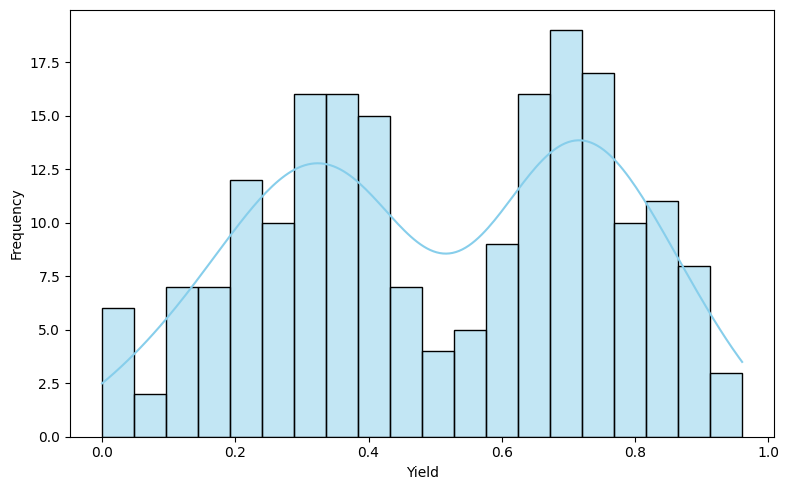

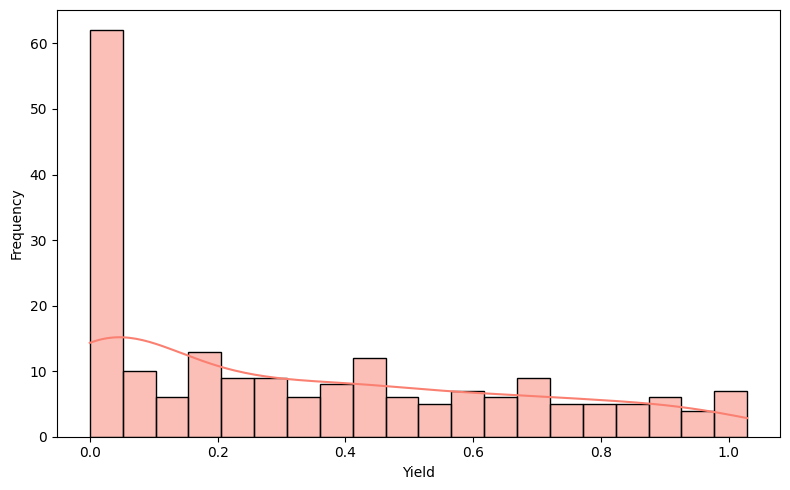

In [10]:
# Extract the yield column from the full dataset
yield_values_train_MP_CF3 = df_dataset1["MP_CF3"].dropna()
yield_values_train_CO_tbu = df_dataset1["CO_tbu"].dropna()

# Plot histogram
plt.figure(figsize=(8, 5))
sns.histplot(yield_values_train_MP_CF3, bins=20, kde=True, color='skyblue', edgecolor='black')

plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.grid(False)
plt.tight_layout()
plt.show()

# Plot histogram
plt.figure(figsize=(8, 5))
sns.histplot(yield_values_train_CO_tbu, bins=20, kde=True, color='salmon', edgecolor='black')

plt.xlabel("Yield")
plt.ylabel("Frequency")
plt.grid(False)
plt.tight_layout()
plt.show()


# Featurizing final library 

In [ ]:
final_library = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
final_library_controls = control_h5

# Dataset 1 Full library
full_library_ds1 = extract_uvvis_normalized(final_library)
full_library_ds1.to_csv("Featurized datasets/Full Library/Full Library Dataset 1.csv", index=False)

# Dataset 2 Full library
full_library_ds2 = extract_control_spectra_normalized(final_library, final_library_controls)
full_library_ds2.to_csv("Featurized datasets/Full Library/Full Library Dataset 2.csv", index=False)

# Dataset 3 Full library
full_library_ds3 = extract_peak_features(final_library, final_library_controls)
full_library_ds3.to_csv("Featurized datasets/Full Library/Full Library Dataset 3.csv", index=False)

# Dataset 4 Full library
full_library_ds4 = extract_peak_features_deltas(final_library, final_library_controls)
full_library_ds4.to_csv("Featurized datasets/Full Library/Full Library Dataset 4.csv", index=False)

# Dataset 5 Full library
full_library_ds5 = extract_sample_peak_features(final_library)
full_library_ds5.to_csv("Featurized datasets/Full Library/Full Library Dataset 5.csv", index=False)

# Note: The code above extracts features and labels them in numerical order according to dataset name.
# A previous version of this code featured datasets with different naming conventions, which have since
# been deprecated. However, results from these original datasets were used for modeling, and therefore
# the current dataset files retain the original order for consistency.

# One Hot Encoded Features

In [ ]:
# One Hot Encode Training Dataset
ref_file = "HDF5 Datasets/250708 - Final Nickel Spectral Library.h5"
train_file = "HDF5 Datasets/250708 - Training Dataset.h5"

df_one_hot = one_hot_from_hdf5(
    train_file,
    ref_h5_path=ref_file,
    metal_map=metal_map,
    solvent_map=solvent_map
)
df_one_hot = prepare_dataset(df_one_hot, yield_lookup, yield_columns, drop_cols)

# The one-hot dataset keeps its own (alphabetical) sample order, so the seed-42 split in [4]
# gives the one-hot models a different 40-sample test set than Datasets 1-5

df_one_hot.to_csv("Featurized datasets/Training Datasets/One-hot encoded dataset.csv", index=False)

# One Hot Encode Full library
full_library_one_hot = one_hot_from_hdf5(final_library, ref_h5_path=final_library, metal_map=metal_map, solvent_map=solvent_map)
full_library_one_hot.to_csv("Featurized datasets/Full Library/Full Library one-hot encoded.csv", index=False)